# Experiment 4: NeuroCore-32 RISC-V Processor on the PYNQ-Z2

A 32-bit RISC-V processor (RV32I) built in the FPGA fabric. It has the classic
five pipeline stages - fetch, decode, execute, memory, write back - with
forwarding so that back-to-back instructions do not have to wait for each other.

The ARM processor loads a program into the instruction memory over AXI4-Lite,
starts the core, and reads the results out of the data memory when the program
stops itself with an `EBREAK` instruction.

Registers: `0x0000` control (bit 0 run, bit 1 reset), `0x0004` status,
`0x0008` current PC, `0x000C` current instruction, `0x0010`-`0x001C` counters
(cycles, instructions, stalls, branches), `0x1000+` instruction memory,
`0x2000+` data memory.

In [2]:
%matplotlib inline
from pynq import Overlay, MMIO
import matplotlib.pyplot as plt
import time

CTRL, STATUS, PC, INSTR = 0x0000, 0x0004, 0x0008, 0x000C
CYCLES, INSTRS, STALLS, BRANCHES = 0x0010, 0x0014, 0x0018, 0x001C
IMEM, DMEM = 0x1000, 0x2000

overlay = Overlay('system_wrapper.bit')
ip = overlay.ip_dict.get('neurocore_top_0/s_axi') or overlay.ip_dict['neurocore_top_0']
cpu = MMIO(ip['phys_addr'], 0x10000)
print(f"Overlay loaded, processor at 0x{ip['phys_addr']:08X}")

def run_program(words, timeout=2.0):

    cpu.write(CTRL, 0x2)                                      
    time.sleep(0.01)
    for i, word in enumerate(words):
        cpu.write(IMEM + 4 * i, word)
    cpu.write(CTRL, 0x1)                           

    deadline = time.time() + timeout
    while not cpu.read(STATUS) & 0x2:
        if time.time() > deadline:
            raise RuntimeError('the program did not reach EBREAK')
    return {'cycles': cpu.read(CYCLES), 'instructions': cpu.read(INSTRS),
            'stalls': cpu.read(STALLS), 'branches': cpu.read(BRANCHES)}

def read_memory(offset, count):
    return [cpu.read(DMEM + offset + 4 * i) for i in range(count)]


Fibonacci numbers from the FPGA:
[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610, 987, 1597, 2584, 4181]
correct: PASS
171 instructions in 179 cycles = 0.955 IPC


In [3]:
FIBONACCI = [268435603, 20971795, 531, 4235299, 1049235, 5284387, 2097555, 35770979, 5374771, 2200467, 7373875, 6561827, 164403, 197299, 1147283, 4263506031, 1048691]

stats = run_program(FIBONACCI)
numbers = read_memory(0x100, 20)

print('Fibonacci numbers from the FPGA:')
print(numbers)

expected = [0, 1]
while len(expected) < 20:
    expected.append(expected[-1] + expected[-2])
print('correct:', 'PASS' if numbers == expected else 'FAIL')
print()
print(f"{stats['instructions']} instructions in {stats['cycles']} cycles "
      f"= {stats['instructions'] / stats['cycles']:.3f} instructions per cycle")


array after sorting: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
correct: PASS
1411 instructions in 1575 cycles, 120 stalls, 439 branches


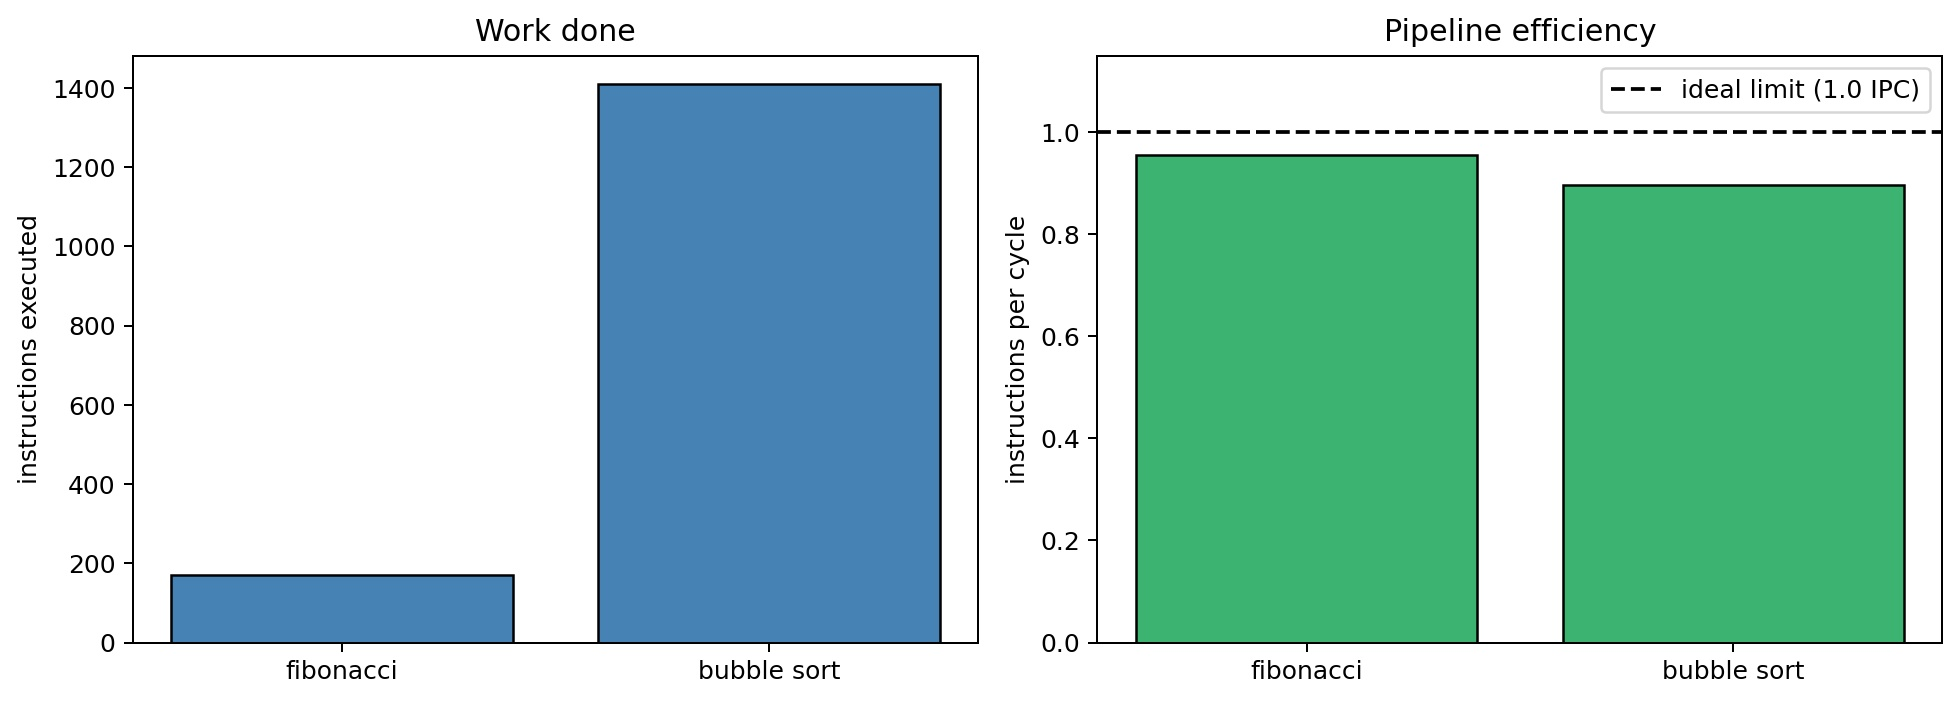

In [4]:
BUBBLE_SORT = [147, 16777491, 403, 15729171, 2219619, 2200211, 5276467, 4399139, 4294050323, 1147283, 4271894639, 1299, 4293985683, 45440611, 1555, 1084589747, 47600739, 2496275, 14714803, 501763, 4696195, 17356387, 18325539, 17277475, 1443347, 4259311727, 1377555, 4238340207, 1048691]

sort_stats = run_program(BUBBLE_SORT)
sorted_values = read_memory(0x000, 16)

print('array after sorting:', sorted_values)
print('correct:', 'PASS' if sorted_values == sorted(sorted_values) else 'FAIL')
print(f"{sort_stats['instructions']} instructions in {sort_stats['cycles']} cycles, "
      f"{sort_stats['stalls']} stalls, {sort_stats['branches']} branches")


In [ ]:
programs = ['fibonacci', 'bubble sort']
ipc = [stats['instructions'] / stats['cycles'],
       sort_stats['instructions'] / sort_stats['cycles']]
counts = [stats['instructions'], sort_stats['instructions']]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].bar(programs, counts, color='steelblue')
axs[0].set_ylabel('instructions executed')
axs[0].set_title('Work done')

axs[1].bar(programs, ipc, color='green')
axs[1].axhline(1.0, color='black', linestyle='--', label='one per cycle')
axs[1].set_ylim(0, 1.1)
axs[1].set_ylabel('instructions per cycle')
axs[1].set_title('Pipeline efficiency')
axs[1].legend()

plt.tight_layout()
plt.show()

print('A perfect pipeline retires one instruction per cycle. Branches and loads')
print('cost a few cycles, which is why the numbers sit just below 1.0.')
